In [1]:
import numpy as np

# 1) Homogeneous Coordinates Representation (2D)

### Convert x into homogeneous coordinates x_H

In [2]:
x = np.array([2, 3])
x_H = np.append(x, 1)
print("Homogeneous coordinate:", x_H)

Homogeneous coordinate: [2 3 1]


### Another homogeneous coordinates equal x

In [3]:
x_H2 = x_H*2
print("Scaled homogeneous coordinate:", x_H2)

Scaled homogeneous coordinate: [4 6 2]


### Convert both back to Cartesian coordinates and verify

In [4]:
x_cartesian_1 = x_H[:-1] / x_H[-1]
x_cartesian_2 = x_H2[:-1] / x_H2[-1]

print("Cartesian from x_H :", x_cartesian_1)
print("Cartesian from x_H2:", x_cartesian_2)
print("x_H represents x :", np.allclose(x_cartesian_1, x))
print("x_H2 represents x:", np.allclose(x_cartesian_2, x))

Cartesian from x_H : [2. 3.]
Cartesian from x_H2: [2. 3.]
x_H represents x : True
x_H2 represents x: True


# 2) Homogeneous Coordinates Representation (3D) 

In [5]:
y = np.array([4,5,6])

### Convert y to homogeneous coordinates y_H

In [6]:
y_H = np.append(y, 1)
print("Homogeneous coordinate:", y_H)

Homogeneous coordinate: [4 5 6 1]


### Multiply it by factor of 2 and convert back to Cartesian coordinates

In [7]:
y_H2 = y_H * 2
print("Multiplied y_H by factor of 2: ", y_H2)

y_cartesian = y_H2[:-1] / y_H2[-1]
print("Converted back to Cartesian: ", y_cartesian)

Multiplied y_H by factor of 2:  [ 8 10 12  2]
Converted back to Cartesian:  [4. 5. 6.]


### Verify result match the original y 

In [8]:
print("y_H2 converted to original y: ", np.allclose(y_cartesian, y))

y_H2 converted to original y:  True


# 3)Affine Transformations in 2D

In [9]:
p = [1,2,1]

### Scale by a factor of 3

In [10]:
S_3 = np.array([
    [3, 0, 0],
    [0, 3, 0],
    [0, 0, 1]
    ])

print("Scale by 3 matrix: \n", S_3)


Scale by 3 matrix: 
 [[3 0 0]
 [0 3 0]
 [0 0 1]]


### Rotate by 45 degree

In [11]:
theta = np.deg2rad(45)

R_45 = np.array([
    [np.cos(theta), -np.sin(theta), 0],
    [np.sin(theta), np.cos(theta), 0],
    [0, 0, 1]
])

print("Rotation by 45 degree matrix: \n", R_45)

Rotation by 45 degree matrix: 
 [[ 0.70710678 -0.70710678  0.        ]
 [ 0.70710678  0.70710678  0.        ]
 [ 0.          0.          1.        ]]


### Translate by (2,3)

In [12]:
T_23 = np.array([
    [1, 0, 2],
    [0, 1, 3],
    [0, 0, 1]
])

print("Translation (2,3) matrix: \n", T_23)

Translation (2,3) matrix: 
 [[1 0 2]
 [0 1 3]
 [0 0 1]]


### Combine

In [13]:
M = T_23 @ R_45 @ S_3

print("Combined transformation matrix:\n", M)

p_combined_result = M @ p
print("Combined result:\n", p_combined_result)

step1 = S_3 @ p
step2 = R_45 @ step1
step3 = T_23 @ step2

print("step by step resul: \n", step3)

print("step and combine results are same: ", np.allclose(p_combined_result, step3))

Combined transformation matrix:
 [[ 2.12132034 -2.12132034  2.        ]
 [ 2.12132034  2.12132034  3.        ]
 [ 0.          0.          1.        ]]
Combined result:
 [-0.12132034  9.36396103  1.        ]
step by step resul: 
 [-0.12132034  9.36396103  1.        ]
step and combine results are same:  True


# 4) Inverse Transformations (2D)

In [14]:
q = np.array([3,4,1])

### Inverse Scale by 2

In [15]:
inv_scale_2 = np.array([
    [1/2, 0, 0],
    [0, 1/2, 0],
    [0, 0, 1]
])

print("Inverse sclae by 2 matrix: \n", inv_scale_2)

Inverse sclae by 2 matrix: 
 [[0.5 0.  0. ]
 [0.  0.5 0. ]
 [0.  0.  1. ]]


### Inverse Rotate by 30 degree

In [16]:
theta = np.deg2rad(30)
inv_R_30= np.array([
    [np.cos(-theta), -np.sin(-theta), 0],
    [np.sin(-theta), np.cos(-theta), 0],
    [0, 0, 1]
])

print("Inverse of Rotate by 30 degree matrix: \n", inv_R_30)

Inverse of Rotate by 30 degree matrix: 
 [[ 0.8660254  0.5        0.       ]
 [-0.5        0.8660254  0.       ]
 [ 0.         0.         1.       ]]


### Inverse Translate by (5,5)

In [17]:
inv_T_55 = np.array([
    [1, 0 , -5],
    [0, 1, -5],
    [0, 0, 1]
])
print("Inverse of Translation (5,5): \n", inv_T_55)

Inverse of Translation (5,5): 
 [[ 1  0 -5]
 [ 0  1 -5]
 [ 0  0  1]]


### Combine Transformations

In [18]:
inv_M = inv_scale_2 @ inv_R_30 @ inv_T_55

print("Combined inverse transformation matrix:\n", inv_M)

q_inv_combined_result = inv_M @ q 

print("Inversed q combined result: \n", q_inv_combined_result)


Combined inverse transformation matrix:
 [[ 0.4330127   0.25       -3.41506351]
 [-0.25        0.4330127  -0.91506351]
 [ 0.          0.          1.        ]]
Inversed q combined result: 
 [-1.1160254  0.0669873  1.       ]


### Verification

In [19]:
S_2 = np.array([
    [2, 0, 0],
    [0, 2, 0],
    [0, 0, 1]
])

R_30 = np.array([
    [np.cos(theta), -np.sin(theta), 0],
    [np.sin(theta),  np.cos(theta), 0],
    [0, 0, 1]
])

T_55 = np.array([
    [1, 0, 5],
    [0, 1, 5],
    [0, 0, 1]
])

M = T_55 @ R_30 @ S_2

numpy_inverse = np.linalg.inv(M)

print("Our inverse is correct:",
      np.allclose(inv_M, numpy_inverse))

Our inverse is correct: True


# 5) Transformations Between 3D Coordinate Systems

In [20]:
r_A = np.array([3, 3, 3, 1])

### System A (origin (1, 1, 1))

In [21]:
T_WA = np.array([
    [1, 0, 0, 1],
    [0, 1, 0, 1],
    [0, 0, 1, 1],
    [0, 0, 0, 1]
])

print("A to World:\n", T_WA)

A to World:
 [[1 0 0 1]
 [0 1 0 1]
 [0 0 1 1]
 [0 0 0 1]]


### System B origin at (2,2,2) and rotated by 90 degree around Z axis

In [22]:
theta = np.deg2rad(90)

T_R = np.array([
    [np.cos(theta), -np.sin(theta), 0],
    [np.sin(theta), np.cos(theta), 0],
    [0, 0, 1]
])

T_O = np.array([2,2,2])

T_WB= np.eye(4)

T_WB[:3,:3] = T_R
T_WB[:3, 3] = T_O


print("B to World:\n", T_WB)

B to World:
 [[ 6.123234e-17 -1.000000e+00  0.000000e+00  2.000000e+00]
 [ 1.000000e+00  6.123234e-17  0.000000e+00  2.000000e+00]
 [ 0.000000e+00  0.000000e+00  1.000000e+00  2.000000e+00]
 [ 0.000000e+00  0.000000e+00  0.000000e+00  1.000000e+00]]


### Convert r in System A to System B

In [23]:
T_BW = np.linalg.inv(T_WB)
T_BA= T_BW @ T_WA 

print("A to B transformation:\n", T_BA)

A to B transformation:
 [[ 6.123234e-17  1.000000e+00  0.000000e+00 -1.000000e+00]
 [-1.000000e+00  6.123234e-17  0.000000e+00  1.000000e+00]
 [ 0.000000e+00  0.000000e+00  1.000000e+00 -1.000000e+00]
 [ 0.000000e+00  0.000000e+00  0.000000e+00  1.000000e+00]]


In [24]:
r_B = T_BA @ r_A

print("Point in System B:", r_B[:3])

Point in System B: [ 2. -2.  2.]


# 6) Projection in Camera Coordinates (3D to 2D)

In [25]:
P = np.array([1,2,5])

K = np.array([
    [1000, 0, 500],
    [0, 1000, 500],
    [0, 0, 1]
])

### Projected homogeneous point

In [26]:
p_projected = K @ P

print("Projected homogeneous point:", p_projected)


Projected homogeneous point: [3500 4500    5]


### 2D pixel coordinates

In [27]:
pixel = p_projected[:2] / p_projected[2]

print("2D pixel coordinates:", pixel)

2D pixel coordinates: [700. 900.]


### \(K^*\) is the intrinsic camera matrix. Here, \(f_x=1000\) and \(f_y=1000\) are the focal lengths in pixel units. The principal point is \((c_x,c_y)=(500,500)\), which is where the optical axis intersects the image plane. The skew value is \(0\), meaning the image axes are perpendicular.

# 7) General Camera Model (3D world Point to 2D Image)

In [28]:
K = np.array([
    [1200, 0, 640],
    [0, 1200, 360],
    [0, 0, 1]
])

R = np.eye(3)

t = np.array([0, 0, -10])

X_W = np.array([2, 3, 4, 1])

### Compute the extrinsic matrix 

In [29]:
extrinsic = np.eye(4)

extrinsic[:3, :3] = R.T
extrinsic[:3, 3] = -R.T @ t

print("Extrinsic matrix:\n", extrinsic)

Extrinsic matrix:
 [[ 1.  0.  0.  0.]
 [ 0.  1.  0.  0.]
 [ 0.  0.  1. 10.]
 [ 0.  0.  0.  1.]]


### Project the point onto the image plane

In [30]:
X_C_h = extrinsic @ X_W

print("Point in camera coordinates:", X_C_h)

X_C = X_C_h[:3]

p_projected = K @ X_C

print("Projected homogeneous point:", p_projected)



Point in camera coordinates: [ 2.  3. 14.  1.]
Projected homogeneous point: [11360.  8640.    14.]


### 2D coordinates in pixels

In [31]:
pixel = p_projected[:2] / p_projected[2]

print("2D pixel coordinates:", pixel)

2D pixel coordinates: [811.42857143 617.14285714]


# 8) Image Transformation using CV

In [32]:
import cv2
import matplotlib.pyplot as plt
import numpy as np

In [33]:
img = cv2.imread("car.jpg")

img_rgb = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

h, w = img.shape[:2]

cx = w / 2
cy = h / 2

print("Image size:", w, "x", h)
print("Center:", (cx, cy))

Image size: 4000 x 5600
Center: (2000.0, 2800.0)


In [34]:
T = np.array([
    [1, 0, 50],
    [0, 1, 30],
    [0, 0, 1]
], dtype=float)

theta = np.deg2rad(30)

R = np.array([
    [np.cos(theta), -np.sin(theta), 0],
    [np.sin(theta),  np.cos(theta), 0],
    [0,              0,             1]
])

T_to_origin = np.array([
    [1, 0, -cx],
    [0, 1, -cy],
    [0, 0, 1]
])

T_back = np.array([
    [1, 0, cx],
    [0, 1, cy],
    [0, 0, 1]
])

R_center = T_back @ R @ T_to_origin

S = np.array([
    [1.5, 0,   0],
    [0,   1.5, 0],
    [0,   0,   1]
])

S_center = T_back @ S @ T_to_origin



In [35]:
M = S_center @ R_center @ T
print("Combined transformation matrix:\n", M)

M_affine = M[:2, :]

transformed = cv2.warpAffine(
    img_rgb,
    M_affine,
    (w, h)
)

Combined transformation matrix:
 [[ 1.29903811e+00 -7.50000000e-01  1.54437569e+03]
 [ 7.50000000e-01  1.29903811e+00 -2.26083555e+03]
 [ 0.00000000e+00  0.00000000e+00  1.00000000e+00]]


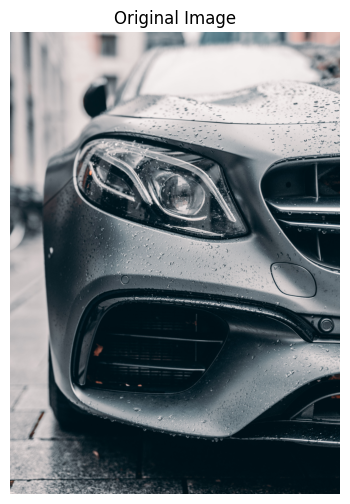

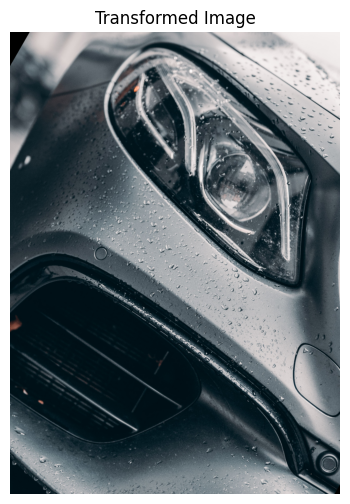

In [36]:
plt.figure(figsize=(8, 6))
plt.imshow(img_rgb)
plt.title("Original Image")
plt.axis("off")
plt.show()

plt.figure(figsize=(8, 6))
plt.imshow(transformed)
plt.title("Transformed Image")
plt.axis("off")
plt.show()

# 9) Order of Transformations

In [37]:
s = np.array([1, 1, 1])

In [38]:
theta = np.deg2rad(90)

R_90 = np.array([
    [np.cos(theta), -np.sin(theta), 0],
    [np.sin(theta),  np.cos(theta), 0],
    [0,              0,             1]
])

S_2 = np.array([
    [2, 0, 0],
    [0, 2, 0],
    [0, 0, 1]
])

T = np.array([
    [1, 0, -1],
    [0, 1,  1],
    [0, 0,  1]
])

In [39]:
M_1 = T @ S_2 @ R_90

result_1 = M_1 @ s

print("Original order result:", result_1)

Original order result: [-3.  3.  1.]


In [40]:
M_2 = R_90 @ S_2 @ T

result_2 = M_2 @ s

print("Reversed order result:", result_2)

Reversed order result: [-4.00000000e+00  2.22044605e-16  1.00000000e+00]


In [41]:
print("Original order:", result_1)
print("Reversed order:", result_2)
print("Are they the same?", np.allclose(result_1, result_2))

Original order: [-3.  3.  1.]
Reversed order: [-4.00000000e+00  2.22044605e-16  1.00000000e+00]
Are they the same? False


### The final position changes because transformation matrices are generally not commutative. Applying rotation, scaling, and translation in a different order changes the intermediate position of the point, resulting in a different final coordinate.